In [425]:
import sys
from pathlib import Path
import numpy as np
import yaml
import jax
import gc
from tqdm.notebook import tqdm
from dataclasses import replace
from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection

ROOT = Path("/home/kzeleznikar/IJS-F1/Koda")
CFG = ROOT / "EI_cutoff" / "config" / "config_ibz.yaml"

# Ensure the root folder is in Python's search path
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import EI.ei_unified as eu
from EI_baths.phase_map_plots import plot_maps, scan_maps
from EI_baths.fixed_baths import (
    plot_bz,
    plot_dispersion,
    plot_energy,
    plot_xi,
    solve_state,
    solve_teff,
)
from utils.cosmetics import apply_plt_style
from utils.logger import logger
from utils.plotting_utils import Plotter
import EI.ei_unified as eu
import EI.ei_jax_2 as ej
import EI.ei_phonon as pb
from EI.ei_anderson import solve_anderson

from utils.logger import logger, tqdm_bar
from utils.plotting_utils import Plotter, plot_cmap, format_ax, add_legend, plot_cmap, plot_phase_diag, color_map
from EI_baths.fixed_baths import k_path, take_path, color_line, solve_state, plot_dispersion


apply_plt_style()
pt = Plotter(show=True, close=False)

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", dpi=300)

FIG_PATH = "/home/kzeleznikar/IJS-F1/Notes/latex/figures/"

In [426]:
from matplotlib.colors import SymLogNorm
import matplotlib.pyplot as plt
import colormaps as cmaps
import jax.numpy as jnp
from matplotlib.colors import LogNorm
from matplotlib.colors import Normalize
from utils.cosmetics import SET1_LIST

In [427]:
with CFG.open("r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

md = cfg["model"]
eq = cfg["equilibrium"]
sc = cfg["scan"]
op = cfg["open_system"]
nk = md["nk"]
bp = md["band"]["pars"]

bd = eu.tb_2d(nk["scan"], **bp)
p = eu.MFPars(**md["mean_field"])

In [428]:
s0 = eu.solve_eq(bd, p, **eq["initial"], **eq["solve"])
d0 = max(abs(float(s0.d)), 1.0e-12)
m0 = float(s0.m)
tc = float(eu.critical_temperature(bd, p, **eq["critical"]))

logger.info(f"Delta_0 = {d0} = {d0 /(8.617 * 1e-5)} K")
logger.info(f"m = {m0}")
logger.info(f"T_c = {tc} = {tc /(8.617 * 1e-5)} K")

kriticna temp bisekcija:   0%|          | 0/80 [00:00<?, ?it/s]

[20:05:59] [INFO    ] Delta_0 = 0.014548330419685318 = 168.83289334670206 K
[20:05:59] [INFO    ] m = -0.9853240052765395
[20:05:59] [INFO    ] T_c = 0.007731271041176404 = 89.72114472758969 K


In [429]:
tg = sc["temperature"]

tn = np.linspace( tg["min_ratio"], tg["max_ratio"], tg["nt"])

t1a = tn * tc
t2a = tn * tc
nt = tg["nt"]

st = ej.mf_state(bd, p, s0.d, s0.m)
t1n, t2n = 0.1, 1.1
t1, t2 = t1n * tc, t2n * tc

In [430]:
bc = op["bath"]
fn = getattr(pb, bc["rate"])
bp = dict(bc["pars"])
ov = bc["baths"]  # one dict per bath, in the order (T1, T2)

bs = tuple(
    fn(t, bd.k, name=f"bath_{i + 1}", **{**bp, **o})
for i, (t, o) in enumerate(zip((t1, t2), ov))
)

es = {**eq["solve"], "prog": False}
se = eu.solve_eq(
    bd, p,
    t=t1,
    d=max(abs(d0), 1.0e-3),
    m=m0,
    **es,
)

sk = {
    "mix": (0.5, 0.5, 0.1),
    "tol": 1.0e-4,
    "nmax": 5000,
    "chk": 100,
    "prog": True,
    "jtol": 1e-1
}

so = ej.solve_fixed(
    bd, p, se.n.copy(), bs,
    d=float(se.d),
    m=float(se.m),
    **sk,
)


ska = {
    "mix": (0.5, 0.5, 0.1),
    "tol": 1.0e-4,
    "nmax": 5000,
    "chk": 10,
    "prog": True,
} 

sol = solve_anderson(
    bd, p, se.n.copy(), bs,
    d=float(se.d), m=float(se.m),
    mem=4, block=128, **ska,
)

st = ej.mf_state(
    bd, p,
    d=float(so.d),
    m=float(so.m),
)

# so = ej.solve_newton(
#     bd, p, se.n.copy(), bs,
#     d=float(se.d),
#     m=float(se.m),
#     tol=1e-4,
#     nmax=50, 
# )

Fixed EI JAX:   0%|          | 0/50 [00:00<?, ?it/s]

Anderson EI JAX:   0%|          | 0/500 [00:00<?, ?it/s]

In [431]:
logger.info(1-sol.m / so.m)
logger.info(1-abs(sol.d / so.d))
logger.info(f"Delta/Delta_0 = {so.d/d0}")

[20:06:08] [INFO    ] -0.18354710861863843
[20:06:08] [INFO    ] -4.195343256586024e+40
[20:06:08] [INFO    ] Delta/Delta_0 = -2.7611261715152656e-54


In [415]:
import time
import EI.ei_ibz as ibz

ns = nk["scan"]
bi, ib = ibz.tb_2d_ibz(ns, **md["band"]["pars"])

# baths rebuilt on the full 120 grid, same pars as bs
bsi = ibz.IbzBaths(tuple(
    fn(t, ib.kf, name=f"bath_{i + 1}", **{**bp, **o})
    for i, (t, o) in enumerate(zip((t1, t2), ov))
), ib)

In [416]:
sei = eu.solve_eq(bi, p, t=t2, d=max(abs(d0), 1.0e-3), m=m0, **es)
logger.info(f"eq   d: {se.d:.12f} vs {sei.d:.12f}")
logger.info(f"eq   m: {se.m:.12f} vs {sei.m:.12f}")

[20:00:42] [INFO    ] eq   d: 0.014548330393 vs 0.000000010996
[20:00:42] [INFO    ] eq   m: -0.985324005304 vs -0.988514389777


In [417]:
n0 = se.n
ni0 = ibz.restrict(n0, ib)
stf = ej.mf_state(bd, p, float(se.d), float(se.m))
sti = ej.mf_state(bi, p, float(se.d), float(se.m))


def timed(f):
    f().block_until_ready()  # first call compiles
    t0 = time.perf_counter()
    out = f().block_until_ready()
    return np.asarray(out), time.perf_counter() - t0


dnf, tf = timed(lambda: ej.total_current(bd, stf, n0, bs))
dni, ti = timed(lambda: ej.total_current(bi, sti, ni0, bsi))
dnf = dnf.reshape(2, ns, ns)
dni = ibz.unfold(dni, ib)
logger.info(f"cur  max|ibz - full| = {np.abs(dni - dnf).max():.2e}, "
            f"max|dn| = {np.abs(dnf).max():.2e}")
logger.info(f"cur  time full {tf:.3f} s, ibz {ti:.3f} s")

[20:00:43] [INFO    ] cur  max|ibz - full| = 5.55e-17, max|dn| = 2.06e-01
[20:00:43] [INFO    ] cur  time full 0.025 s, ibz 0.007 s


In [418]:
soi = ej.solve_fixed(
    bi, p, ni0.copy(), bsi,
    d=float(se.d),
    m=float(se.m),
    **sk,
)

nf = so.n.reshape(2, ns, ns)
logger.info(f"fix  d: {so.d:.10f} vs {soi.d:.10f} (anderson {sol.d:.10f})")
logger.info(f"fix  m: {so.m:.10f} vs {soi.m:.10f} (anderson {sol.m:.10f})")
logger.info(f"fix  it: {so.it} vs {soi.it}, ok: {so.ok} vs {soi.ok}")
logger.info(f"fix  max|n_ibz - n_full| = {np.abs(ibz.unfold(soi.n, ib) - nf).max():.2e}")
logger.info(f"fix  C4v of full sol = "
            f"{np.abs(ibz.unfold(ibz.restrict(so.n, ib), ib) - nf).max():.2e}")

Fixed EI JAX:   0%|          | 0/50 [00:00<?, ?it/s]

[20:00:52] [INFO    ] fix  d: -0.0000000000 vs -0.0000000000 (anderson 0.0000000000)
[20:00:52] [INFO    ] fix  m: -0.8352164443 vs -0.8355455167 (anderson -0.9885180078)
[20:00:52] [INFO    ] fix  it: 900 vs 1000, ok: True vs True
[20:00:52] [INFO    ] fix  max|n_ibz - n_full| = 5.37e-03
[20:00:52] [INFO    ] fix  C4v of full sol = 1.11e-16


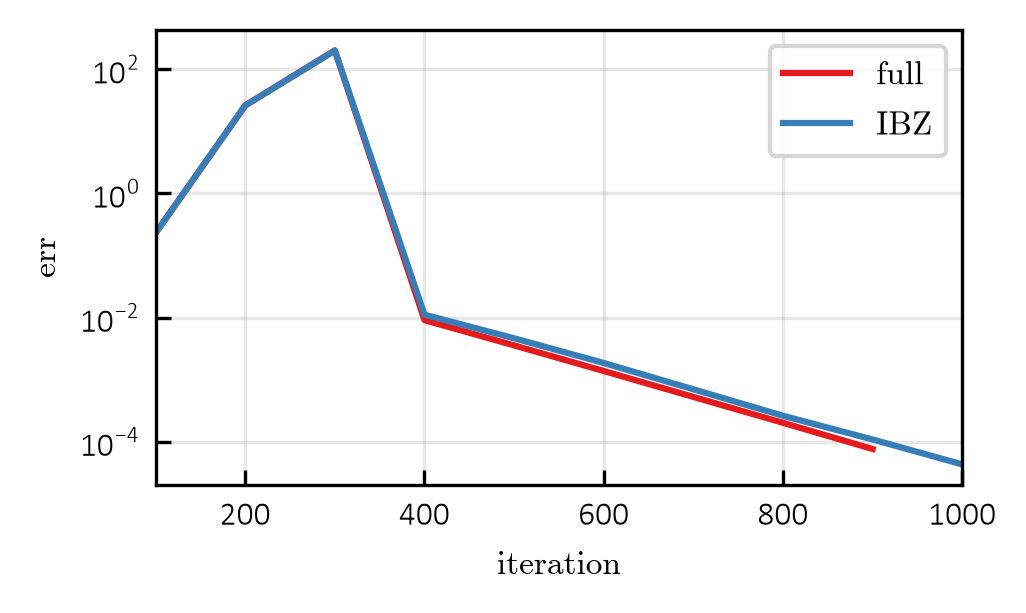

In [419]:
h = 0.6
fig, ax = plt.subplots(figsize=(3.47412, h * 3.47412))
for i, (s, lb) in enumerate(((so, r"$\mathrm{full}$"), (soi, r"$\mathrm{IBZ}$"))):
    ax.semilogy(s.hist["it"], s.hist["err"], color=SET1_LIST[i], label=lb)
it = np.concatenate((so.hist["it"], soi.hist["it"]))
ax.set_xlim(it.min(), it.max())
ax.set_xlabel(r"$\mathrm{iteration}$")
ax.set_ylabel(r"$\mathrm{err}$")
ax.grid(alpha=0.3)
ax.legend()
ax.tick_params(which="both", direction="in")
plt.tight_layout()

In [420]:
ns = nk["ibz"]
bi, ib = ibz.tb_2d_ibz(ns, **md["band"]["pars"])

# baths rebuilt on the full 120 grid, same pars as bs
bsi = ibz.IbzBaths(tuple(
    fn(t, ib.kf, name=f"bath_{i + 1}", **{**bp, **o})
    for i, (t, o) in enumerate(zip((t1, t2), ov))
), ib)

In [421]:
# start state directly on the IBZ, same settings as se
sei = eu.solve_eq(
    bi, p, t=t2,
    d=max(abs(d0), 1.0e-3), m=m0,
    **es,
)

soi = ej.solve_fixed(
    bi, p, sei.n.copy(), bsi,
    d=float(sei.d),
    m=float(sei.m),
    **sk,
)

logger.info(f"d: 60 full {so.d:.8f}, 120 ibz {soi.d:.8f}")
logger.info(f"m: 60 full {so.m:.8f}, 120 ibz {soi.m:.8f}")

# the 60 grid is every second point of the 120 grid
# n120 = ibz.unfold(soi.n, ib)[:, ::2, ::2]
# n60 = so.n.reshape(2, nk["scan"], nk["scan"])
# logger.info(f"max|n120 - n60| on shared k = {np.abs(n120 - n60).max():.2e}")

Fixed EI JAX:   0%|          | 0/50 [00:00<?, ?it/s]

[20:01:07] [INFO    ] d: 60 full -0.00000000, 120 ibz 0.00000000
[20:01:07] [INFO    ] m: 60 full -0.83521644, 120 ibz -0.83397080


In [422]:
from dataclasses import replace


def to_full(sol, ib, bdf):
    """IBZ OpenSol -> OpenSol on the full grid bdf, for the old plot functions."""
    f = lambda a: ibz.unfold(a, ib).reshape(np.shape(a)[:-1] + (-1,))
    s = sol.st
    st = replace(s, bd=bdf, eah=f(s.eah), ebh=f(s.ebh),
                 e=f(s.e), u=f(s.u), v=f(s.v))
    return replace(sol, n=f(sol.n), eta=f(sol.eta), cur=f(sol.cur), st=st)

In [423]:
import dataclasses
import EI.eff_T as et

et.ej = ej      # route eff_T through ei_jax_2 in this kernel
mc = 0.0        # chemical potential; ei_jax_2 energies already carry -V/2
ep = {
    "dt": 0.1, "mix": [0.1, 0.1], "tol": 1.0e-4,
    "nmax": 50, "chk": 10, "mf": False, "prog": True,
    "mode": "dense", "block": 1024,
}


sf = solve_teff(bd, p, bs, so, t1, t2, mc, op, ep)
sf = dataclasses.replace(sf, st=so.st)   # same d, m since mf=False

logger.info("Delta = %.6f, m = %.6f", so.d, so.m)
logger.info("T_eff/T_c = %.6f, power = %.3e, ok = %s",
            sf.t / tc, sf.power, sf.ok)

Effective temperature:   0%|          | 0/50 [00:00<?, ?it/s]

[20:01:12] [WARNING ] Effective-temperature solver did not converge: err = 1.574e+02
[20:01:12] [INFO    ] Delta = -0.000000, m = -0.835216
[20:01:12] [INFO    ] T_eff/T_c = 1.037941, power = 3.895e-04, ok = False


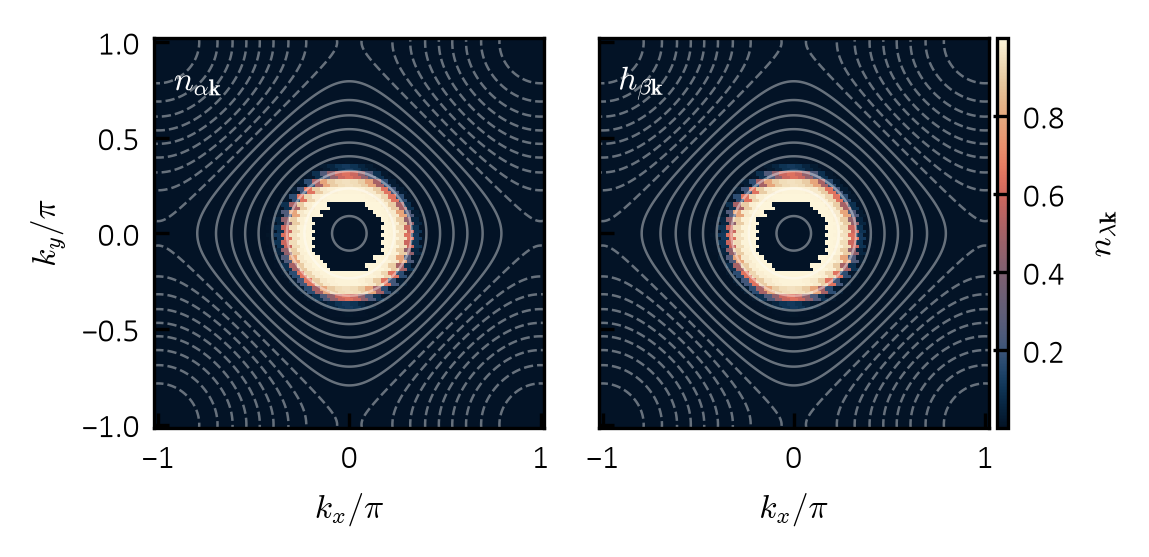

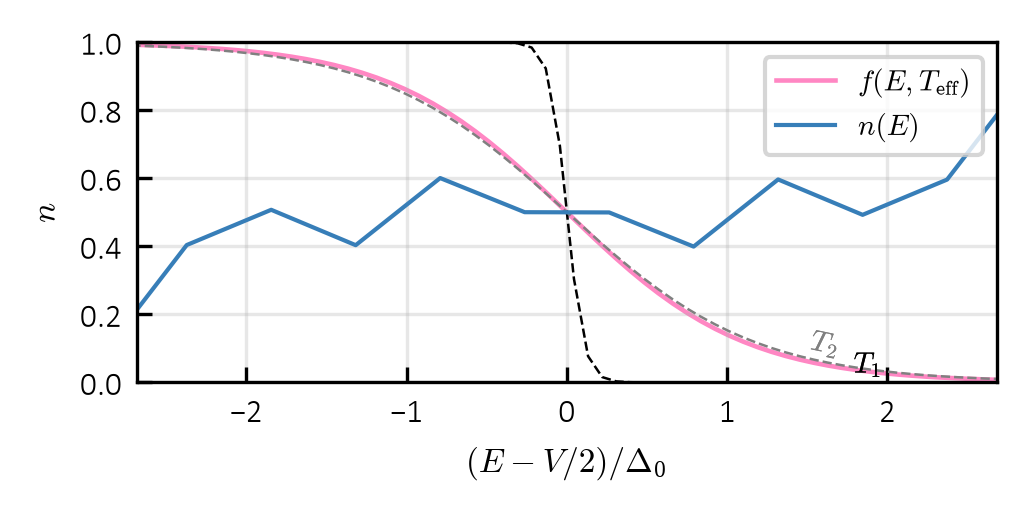

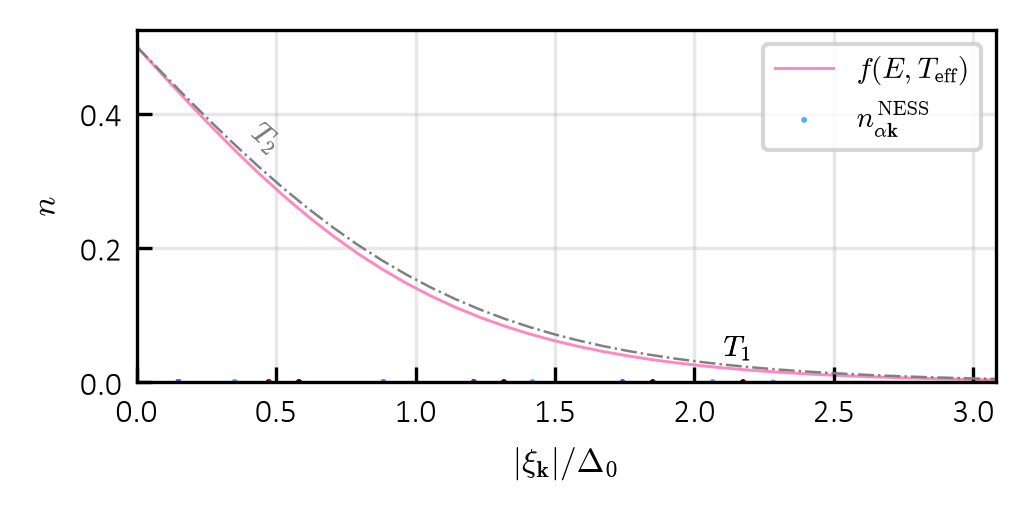

In [424]:
bdf = eu.tb_2d(ns, **md["band"]["pars"])  # full grid, same order as ib.kf
sof = to_full(soi, ib, bdf)
bsf = bsi.bs                              # the plain bath tuple on the full grid

plot_bz(pt, bdf, sof, path=None)
plot_energy(pt, sof, sf, t1, t2, mc, d0, path=None, nb=200)
plot_xi(pt, bdf, p, eq, sof, sf, bsf, t1, t2, d0, path=None, nb=100)

In [386]:
import gc, time

bq = dict(bc["pars"])           # bath pars, same as bp at this point
kw = {**sk, "prog": False}


def setup(n, red):
    """Bands, baths and start state on an n grid; red: use the IBZ."""
    if red:
        b, ib = ibz.tb_2d_ibz(n, **md["band"]["pars"])
        kg = ib.kf
    else:
        b = eu.tb_2d(n, **md["band"]["pars"])
        kg = b.k
    bb = tuple(fn(t, kg, name=f"bath_{i + 1}", **{**bq, **o})
               for i, (t, o) in enumerate(zip((t1, t2), ov)))
    if red:
        bb = ibz.IbzBaths(bb, ib)
    s = eu.solve_eq(b, p, t=t2, d=max(abs(d0), 1.0e-3), m=m0, **es)
    return b, bb, s
def mem_gb(n):
    """GB of one pair array (full, IBZ block) and of all line tables."""
    nf = n * n
    ni = (n // 2 + 1) * (n // 2 + 2) // 2
    nw = int(np.ceil(bs[0].em / (min(q.gam for q in bs) / 8.0))) + 2
    lt = len(bs) * 4 * nf * nw * 8 if bs[0].nsub > 0 else 0
    return (2 * nf) ** 2 * 8e-9, 2 * ni * 2 * nf * 8e-9, lt * 1e-9
def run(n, red):
    """Wall time of solve_fixed, or nan if it fails (e.g. out of memory)."""
    try:
        b, bb, s = setup(n, red)
        t0 = time.perf_counter()
        so = ej.solve_fixed(b, p, s.n.copy(), bb,
                            d=float(s.d), m=float(s.m), **kw)
        out = (time.perf_counter() - t0, so)
    except Exception as er:
        logger.warning(f"nk={n} red={red}: {type(er).__name__}: {er}")
        out = (np.nan, None)
    pb._ltab.cache_clear()  # old line tables stay in host memory otherwise
    jax.clear_caches()
    gc.collect()
    return out

In [387]:
# nks = np.arange(10, 121, 10)  # even only, for the IBZ
# nfm = 65                       # largest nk tried on the full BZ
# res = {q: [] for q in ("nk", "tf", "ti", "itf", "iti", "df", "di")}

# for n in nks:
#     ti, si = run(n, True)
#     tf, sf = run(n, False) if n <= nfm else (np.nan, None)
#     mf, mi, ml = mem_gb(n)
#     res["nk"].append(n)
#     res["tf"].append(tf)
#     res["ti"].append(ti)
#     res["itf"].append(sf.it if sf else np.nan)
#     res["iti"].append(si.it if si else np.nan)
#     res["df"].append(sf.d if sf else np.nan)
#     res["di"].append(si.d if si else np.nan)
#     logger.info(f"nk={n}: t full {tf:.1f} s, ibz {ti:.1f} s | "
#                 f"pair {mf:.2f} / {mi:.2f} GB, ltab {ml:.2f} GB")

# res = {q: np.asarray(v, dtype=float) for q, v in res.items()}
# # np.savez("ibz_timing.npz", **res)

In [388]:
# h = 0.6
# fig, ax = plt.subplots(figsize=(3.47412, h * 3.47412))
# ax.plot(res["nk"], res["tf"], "o-", color=SET1_LIST[0], label=r"$\mathrm{BZ}$")
# ax.plot(res["nk"], res["ti"], "s-", color=SET1_LIST[1], label=r"$\mathrm{IBZ}$")
# # ax.set_xlim(res["nk"][0], res["nk"][-1])
# ax.set_xlabel(r"$N_k$")
# ax.set_ylabel(r"$t_\mathrm{gpu}\ [\mathrm{s}]$")
# ax.grid(alpha=0.3)
# ax.legend()
# ax.tick_params(which="both", direction="in")
# plt.tight_layout()

In [389]:
# t1r = np.linspace(0.01, 2.0, 10)    # T1 / Tc
# t2r = np.linspace(0.01, 1.3, 10)    # T2 / Tc

# dm = np.full((t2r.size, t1r.size), np.nan)    # Delta, rows = T2
# mm, em = np.full_like(dm, np.nan), np.full_like(dm, np.nan)
# ok = np.zeros(dm.shape, dtype=bool)

# kf = {**sk, "prog": False}
# s0 = sei    # row seed, always at the low T1 end
# ds = 0.05 * abs(float(d0))
# nw = 100                   # warm-up iterations

# for i in tqdm(range(t2r.size), desc="T2 sweep"):
#     sv = s0
#     for j in tqdm(range(t1r.size), desc="T1 sweep", leave=False):
#         bq = ibz.IbzBaths(tuple(
#             fn(float(t), ib.kf, name=f"bath_{b + 1}", **{**bp, **o})
#             for b, (t, o) in enumerate(zip((t1r[j] * tc, t2r[i] * tc), ov))
#         ), ib)
#         # floor the seeded gap
#         dg = max(abs(float(sv.d)), ds)
#         sn = ej.solve_fixed(bi, p, sv.n.copy(), bq,
#                             d=dg, m=float(sv.m), **kf)
#         # retry from a warm-up if it fell to zero
#         # if abs(float(sn.d)) < ds:
#         #     w0 = ej.solve_fixed(bi, p, sn.n.copy(), bq, d=ds,
#         #                         m=float(sn.m), **{**kf, "nmax": nw})
#         #     sn = ej.solve_fixed(bi, p, w0.n.copy(), bq, d=float(w0.d),
#         #                         m=float(w0.m), **kf)
#         dm[i, j], mm[i, j], em[i, j] = sn.d, sn.m, sn.err
#         ok[i, j] = bool(sn.ok) and np.isfinite(sn.err) and sn.err < kf["tol"]
#         if np.isfinite(sn.err):
#             sv = sn
#         if j == 0 and np.isfinite(sn.err):
#             s0 = sn    # next row starts here

# print("unconverged:", (~ok).sum(), "of", ok.size)

In [390]:
# dz = np.where(ok, np.abs(dm), np.nan) / d0
# mz = np.where(ok, mm, np.nan)

# fd, _ = plot_cmap(t1r, t2r, dm / d0, r"$\Delta/\Delta_0$", pt=pt)
# # fd.savefig(FIG_PATH + "gap_map_test.pdf", bbox_inches="tight")

# fm, _ = plot_cmap(t1r, t2r, mm, r"$m$", pt=pt,
#                   cmap=cmaps.lapaz.cut(0.1, "right"))
# # fm.savefig(FIG_PATH + "m_map_test.pdf", bbox_inches="tight")

In [391]:
ns = nk["ibz"]
bi, ib = ibz.tb_2d_ibz(ns, **md["band"]["pars"])
bf = tuple(fn(t, ib.kf, name=f"bath_{i + 1}", **{**bp, **o})
           for i, (t, o) in enumerate(zip((t1, t2), ov)))

wb = ibz.WinBaths(bf, ib, smin=1.9, smax=2.0)
sei = eu.solve_eq(bi, p, t=t2, d=max(abs(d0), 1.0e-3), m=m0, **es)
n0 = ibz.freeze(sei.n, bi, p, wb)

sow = ej.solve_fixed(bi, p, n0, wb, d=float(sei.d), m=float(sei.m), **sk)

Fixed EI JAX:   0%|          | 0/50 [00:00<?, ?it/s]

In [392]:
soi = ej.solve_fixed(bi, p, sei.n.copy(), ibz.IbzBaths(bf, ib),
                     d=float(sei.d), m=float(sei.m), **sk)
print(sow.d - soi.d, sow.m - soi.m, np.abs(sow.n - soi.n).max())

Fixed EI JAX:   0%|          | 0/50 [00:00<?, ?it/s]

2.6487631402106263e-13 -0.005265412174188189 0.1733312621869061


In [393]:
bq = dict(bc["pars"])  # bath pars
kw = {**sk, "prog": False}


def setup(n):
    """IBZ bands, full grid baths and the equilibrium start on an n grid."""
    bi, ib = ibz.tb_2d_ibz(n, **md["band"]["pars"])
    bf = tuple(fn(t, ib.kf, name=f"bath_{i + 1}", **{**bq, **o})
               for i, (t, o) in enumerate(zip((t1, t2), ov)))
    s = eu.solve_eq(bi, p, t=t2, d=max(abs(d0), 1.0e-3), m=m0, **es)
    return bi, ib, bf, s

def rate_mem(b, bb):
    """GB of one compiled rate build: temporaries + inputs + outputs."""
    bp_, rf_ = ej._baths(bb)
    st_ = ej.mf_state(b, p, d0, m0)
    ma = ej._rates_jit.lower(st_, bp_, rf=rf_).compile().memory_analysis()
    return (ma.temp_size_in_bytes + ma.argument_size_in_bytes
            + ma.output_size_in_bytes) * 1e-9

def run(b, bb, n0, s):
    """Wall time of solve_fixed and its solution, nan on failure."""
    try:
        t0 = time.perf_counter()
        so = ej.solve_fixed(b, p, n0, bb, d=float(s.d), m=float(s.m), **kw)
        out = (time.perf_counter() - t0, so)
    except Exception as er:
        logger.warning(f"{type(er).__name__}: {er}")
        out = (np.nan, None)
    pb._ltab.cache_clear()
    jax.clear_caches()
    gc.collect()
    return out

In [395]:
nks = np.arange(20, 161, 10)    # even only
nmi = 100                        # largest nk for the plain IBZ
sw = (1.8, 2)                 # fixed s window

res = {q: [] for q in ("nk", "ti", "tw", "mi", "mw", "di", "dw", "fw")}
for n in nks:
    bi, ib, bf, s = setup(n)
    bi_, bw_ = ibz.IbzBaths(bf, ib), ibz.WinBaths(bf, ib, *sw)
    wi, _ = ibz.win_index(ib, *sw)

    mw = rate_mem(bi, bw_)
    tw, sw_ = run(bi, bw_, ibz.freeze(s.n, bi, p, bw_), s)
    if n <= nmi:
        mi = rate_mem(bi, bi_)
        ti, si_ = run(bi, bi_, s.n.copy(), s)
    else:
        mi, ti, si_ = np.nan, np.nan, None

    res["nk"].append(n)
    res["ti"].append(ti)
    res["tw"].append(tw)
    res["mi"].append(mi)
    res["mw"].append(mw)
    res["di"].append(si_.d if si_ else np.nan)
    res["dw"].append(sw_.d if sw_ else np.nan)
    res["fw"].append(wi.size / ib.mult.size)
    logger.info(f"nk={n}: t ibz {ti:.1f} s, win {tw:.1f} s | "
                f"mem ibz {mi:.2f} GB, win {mw:.2f} GB | N_W/N_I = {res['fw'][-1]:.3f}")


[15:28:18] [INFO    ] nk=20: t ibz 1.2 s, win 1.2 s | mem ibz 0.02 GB, win 0.00 GB | N_W/N_I = 0.061
[15:28:21] [INFO    ] nk=30: t ibz 1.2 s, win 1.2 s | mem ibz 0.07 GB, win 0.01 GB | N_W/N_I = 0.051
[15:28:26] [INFO    ] nk=40: t ibz 1.3 s, win 1.3 s | mem ibz 0.19 GB, win 0.02 GB | N_W/N_I = 0.043
[15:28:30] [INFO    ] nk=50: t ibz 1.5 s, win 1.4 s | mem ibz 0.43 GB, win 0.04 GB | N_W/N_I = 0.046
[15:28:36] [INFO    ] nk=60: t ibz 1.6 s, win 1.4 s | mem ibz 0.87 GB, win 0.07 GB | N_W/N_I = 0.042
[15:28:42] [INFO    ] nk=70: t ibz 2.0 s, win 1.3 s | mem ibz 1.58 GB, win 0.11 GB | N_W/N_I = 0.041
[15:28:49] [INFO    ] nk=80: t ibz 3.0 s, win 1.4 s | mem ibz 2.64 GB, win 0.17 GB | N_W/N_I = 0.039
[15:28:57] [INFO    ] nk=90: t ibz 3.2 s, win 1.4 s | mem ibz 4.18 GB, win 0.25 GB | N_W/N_I = 0.038
W1101 15:29:14.052444   72638 bfc_allocator.cc:590] Allocator (GPU_0_bfc) ran out of memory trying to allocate 5.73GiB (rounded to 6153028352) from the lower end requested by op 
If this is ca

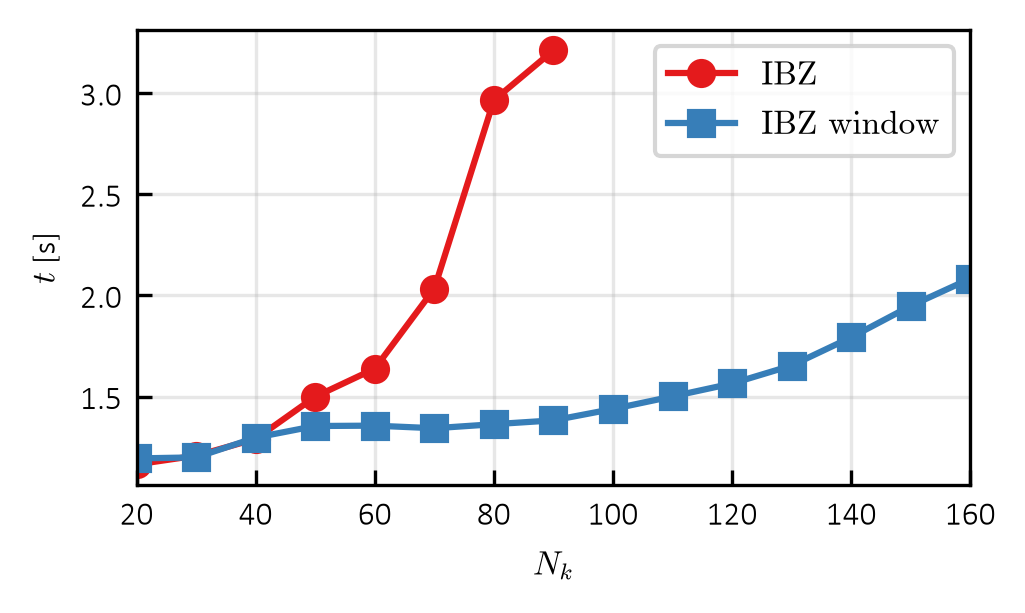

In [ ]:

res = {q: np.asarray(v, dtype=float) for q, v in res.items()}

h = 0.6
fig, ax = plt.subplots(figsize=(3.47412, h * 3.47412))
ax.plot(res["nk"], res["ti"], "o-", color=SET1_LIST[0], label=r"$\mathrm{IBZ}$")
ax.plot(res["nk"], res["tw"], "s-", color=SET1_LIST[1], label=r"$\mathrm{IBZ\ window}$")
ax.set_xlim(res["nk"][0], res["nk"][-1])
ax.set_xlabel(r"$N_k$")
ax.set_ylabel(r"$t$ [s]")
ax.grid(alpha=0.3)
ax.legend()
ax.tick_params(which="both", direction="in")
# plt.savefig(FIG_PATH + "timing_Nk_IBZ_wIBZ.pdf", bbox_inches="tight")
plt.tight_layout()

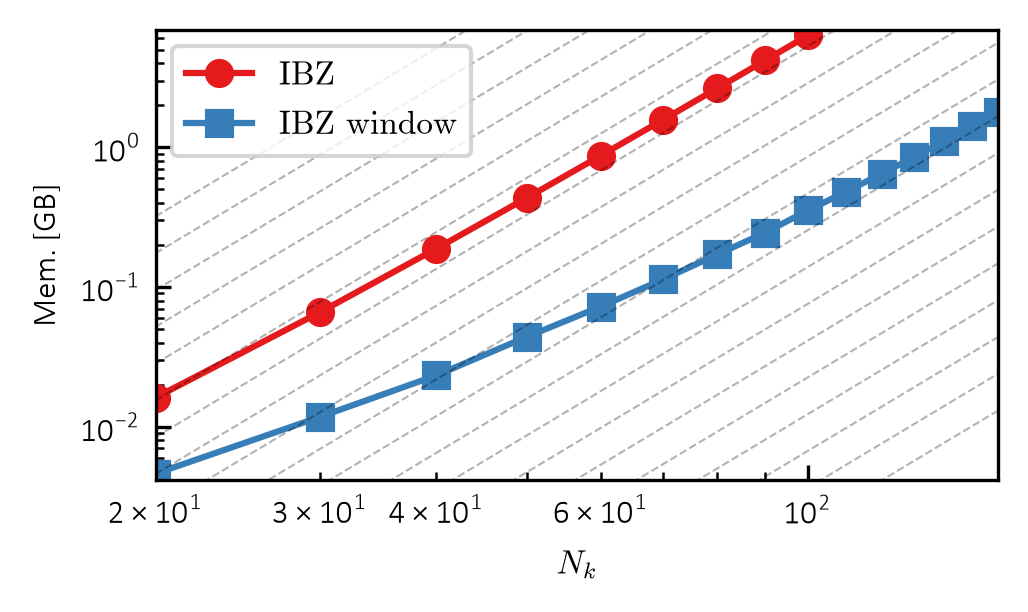

In [ ]:
fig, ax = plt.subplots(figsize=(3.47412, h * 3.47412))
ax.loglog(res["nk"], res["mi"], "o-", color=SET1_LIST[0], label=r"$\mathrm{IBZ}$")
ax.loglog(res["nk"], res["mw"], "s-", color=SET1_LIST[1], label=r"$\mathrm{IBZ\ window}$")
for t in np.geomspace(0.001, 100, 20):
    ax.loglog(res["nk"], res["nk"]**4 * 2e-8 * t, "k--", alpha=0.3, lw=0.5)
ax.set_xlim(res["nk"][0], res["nk"][-1])
ax.set_xlabel(r"$N_k$")
ax.set_ylabel(r"Mem. [GB]")
ax.set_ylim(min(res["mw"]) * 0.90, max(res["mi"]) * 1.1)
ax.legend()
ax.tick_params(which="both", direction="in")
# plt.savefig(FIG_PATH + "mem_Nk_IBZ_wIBZ.pdf", bbox_inches="tight")
plt.tight_layout()

In [398]:
ns = nk["ibz"]
ss = 2.0                              # window centre s*
hws = np.linspace(0.05, 1.0, 12)      # half widths

bi, ib, bf, s = setup(ns)
_, so = run(bi, ibz.IbzBaths(bf, ib), s.n.copy(), s)   # plain IBZ reference

ws = {q: [] for q in ("hw", "fw", "dd", "dm", "dn")}
for hw in tqdm(hws):
    wb = ibz.WinBaths(bf, ib, max(ss - hw, -2.0), min(ss + hw, 2.0))
    wi, _ = ibz.win_index(ib, wb.smin, wb.smax)
    _, sow = run(bi, wb, ibz.freeze(s.n, bi, p, wb), s)
    ok_ = sow is not None
    ws["hw"].append(hw)
    ws["fw"].append(wi.size / ib.mult.size)
    ws["dd"].append(abs(sow.d - so.d) / abs(so.d) if ok_ else np.nan)
    ws["dm"].append(abs(sow.m - so.m) if ok_ else np.nan)
    ws["dn"].append(np.abs(sow.n - so.n).max() if ok_ else np.nan)

ws = {q: np.asarray(v, dtype=float) for q, v in ws.items()}

  0%|          | 0/12 [00:00<?, ?it/s]

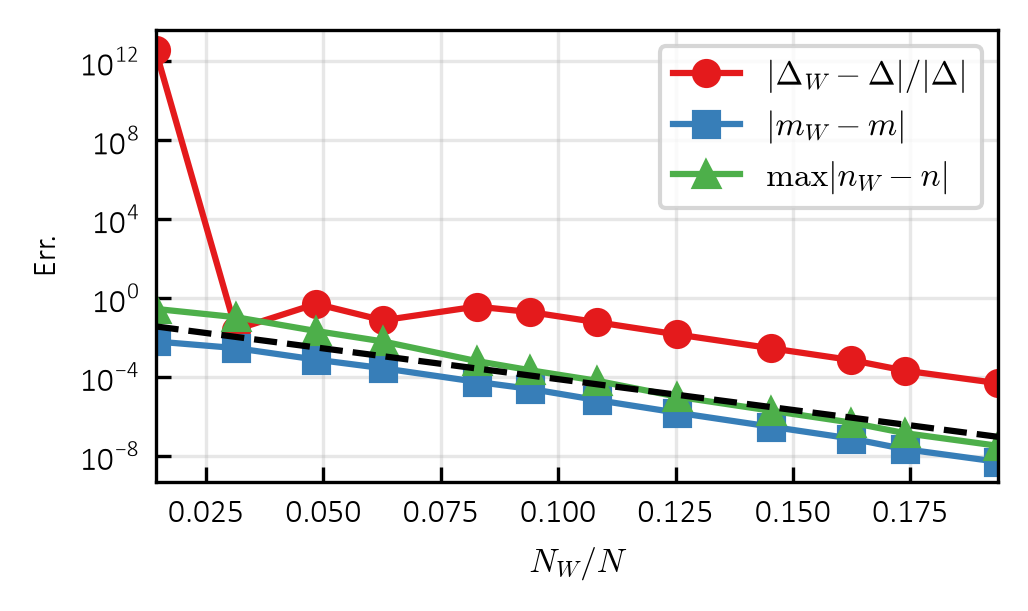

In [399]:
fig, ax = plt.subplots(figsize=(3.47412, h * 3.47412))
# x = 2.0 * ws["hw"]
x = ws["fw"]
ax.semilogy(x, ws["dd"], "o-", color=SET1_LIST[0], label=r"$|\Delta_W-\Delta|/|\Delta|$")
ax.semilogy(x, ws["dm"], "s-", color=SET1_LIST[1], label=r"$|m_W-m|$")
ax.semilogy(x, ws["dn"], "^-", color=SET1_LIST[2], label=r"$\max|n_W-n|$")
ax.semilogy(x, np.exp(-x / t1)* 1e-1, "k--")
ax.set_xlim(x[0], x[-1])
ax.set_xlabel(r"$N_W / N$")
ax.set_ylabel(r"Err.")
ax.grid(alpha=0.3)
ax.legend(ncol=1)
ax.tick_params(which="both", direction="in")
# plt.savefig(FIG_PATH + "err_windowsize_wIBZ.pdf", bbox_inches="tight")
plt.tight_layout()

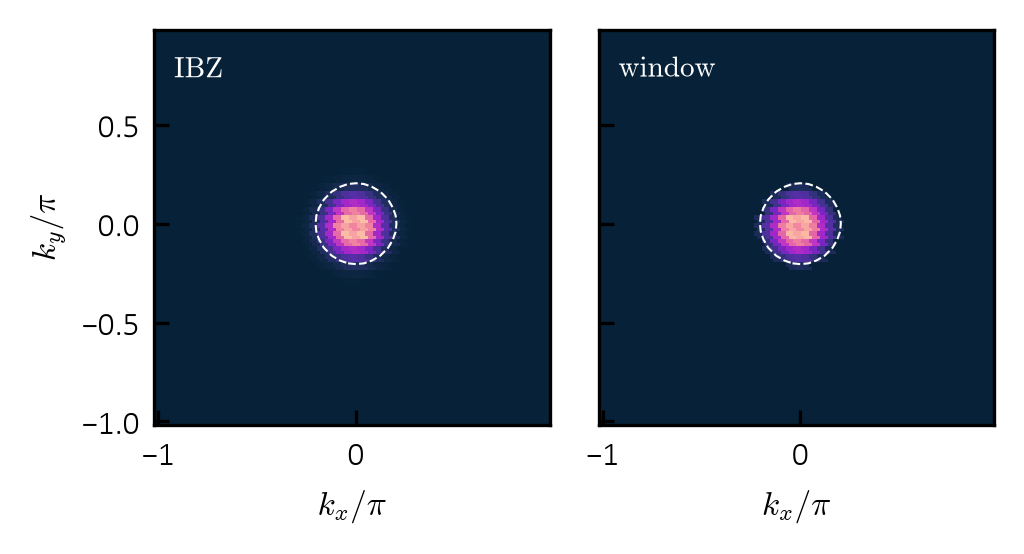

In [400]:
hw = 0.2
wb = ibz.WinBaths(bf, ib, max(ss - hw, -2.0), min(ss + hw, 2.0))
_, sow = run(bi, wb, ibz.freeze(s.n, bi, p, wb), s)
q = np.linspace(-np.pi, np.pi, ns, endpoint=False) / np.pi
na = ibz.unfold(so.n[0], ib)
nw = ibz.unfold(sow.n[0], ib)
sg = np.cos(np.pi * q)[:, None] + np.cos(np.pi * q)[None, :]
vm = max(na.max(), nw.max())
cm = cmaps.bubblegum  # swap in the colormap plot_bz uses
fig, axs = plt.subplots(1, 2, figsize=(3.47412, 0.55 * 3.47412), sharey=True)
for ax, z, lb in zip(axs, (na, nw), (r"$\mathrm{IBZ}$", r"$\mathrm{window}$")):
    im = ax.pcolormesh(q, q, z.T, cmap=cm, vmin=0.0, vmax=vm, shading="nearest")
    im.set_edgecolor("face")
    ax.contour(q, q, sg.T, levels=[wb.smin, wb.smax], colors="w",
               linewidths=0.5, linestyles="--")
    ax.text(0.05, 0.88, lb, transform=ax.transAxes, color="w", fontsize=7)
    ax.set_xlabel(r"$k_x/\pi$")
    ax.set_aspect("equal")
    ax.tick_params(which="both", direction="in")
axs[0].set_ylabel(r"$k_y/\pi$")
# cbar = fig.colorbar(im, ax=axs.tolist())
# cbar.set_label(r"$n_{\alpha\mathbf{k}}$", rotation=90, labelpad=5)
plt.tight_layout()

In [401]:
ns = 200
hw = 0.25  # half width: pick one with a small error in the f scan

bi, ib, bf, s = setup(ns)
wb = ibz.WinBaths(bf, ib, max(ss - hw, -2.0), min(ss + hw, 2.0))
wi, _ = ibz.win_index(ib, wb.smin, wb.smax)
logger.info(f"N_I = {ib.mult.size}, N_W = {wi.size}, f = {wi.size / ib.mult.size:.3f}, "
            f"rate mem {rate_mem(bi, wb):.2f} GB")

tw, sow = run(bi, wb, ibz.freeze(s.n, bi, p, wb), s)
logger.info(f"t = {tw:.1f} s, d = {sow.d:.6f}, m = {sow.m:.6f}, ok = {sow.ok}")

[15:30:49] [INFO    ] N_I = 5151, N_W = 225, f = 0.044, rate mem 4.92 GB
[15:30:53] [INFO    ] t = 4.1 s, d = 0.000000, m = -0.985298, ok = True


In [402]:
q = np.linspace(-np.pi, np.pi, ns, endpoint=False) / np.pi
na = ibz.unfold(sow.n[0], ib)        # n_alpha
hb = 1.0 - ibz.unfold(sow.n[1], ib)  # h_beta = 1 - n_beta
sg = np.cos(np.pi * q)[:, None] + np.cos(np.pi * q)[None, :]
kr = np.hypot(q[:, None], q[None, :])
lim = 1.15 * kr[(sg >= wb.smin) & (sg <= wb.smax)].max()
vm = max(na.max(), hb.max())
cm = cmaps.bubblegum  # swap in the plot_bz colormap

/tmp/ipykernel_72638/3993818472.py:18: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


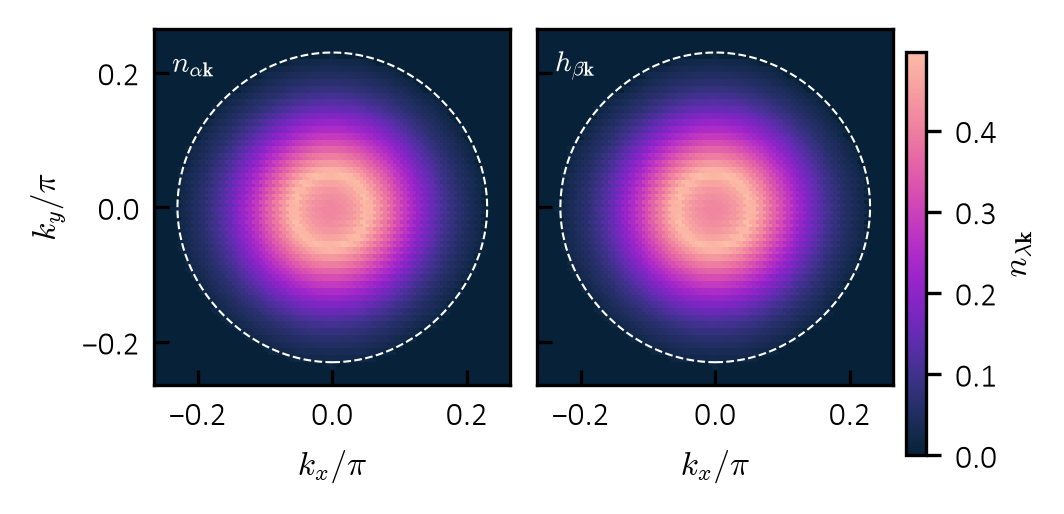

In [403]:
fig, axs = plt.subplots(1, 2, figsize=(3.47412, 0.55* 3.47412), sharey=True)
for ax, z, lb in zip(axs, (na, hb), (r"$n_{\alpha\mathbf{k}}$", r"$h_{\beta\mathbf{k}}$")):
    im = ax.pcolormesh(q, q, z.T, cmap=cm, vmin=0.0, vmax=vm, shading="nearest")
    im.set_edgecolor("face")
    ax.contour(q, q, sg.T, levels=[wb.smin, wb.smax], colors="w",
               linewidths=0.5, linestyles="--")
    ax.text(0.05, 0.88, lb, transform=ax.transAxes, color="w", fontsize=7)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_xlabel(r"$k_x/\pi$")
    ax.tick_params(which="both", direction="in")

axs[0].set_ylabel(r"$k_y/\pi$")

cbar = fig.colorbar(im, ax=axs, fraction=0.025, pad=-0.15)
cbar.set_label(r"$n_{\lambda\mathbf{k}}$", rotation=90, labelpad=1)
plt.tight_layout()